# Gasto público total

In [ ]:
# Parámetros de la gráfica
SLUG = "fiscalidad"  # carpeta en research/temas/
GRAFICA_ID = "gasto-publico-total"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Gasto público total"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% del PIB"  # gasto total de las administraciones públicas sobre el PIB a precios corrientes
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None  # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** Todo lo que gastan en un año las administraciones públicas (en España, la Administración central, las comunidades autónomas, las entidades locales y la Seguridad Social), en porcentaje del PIB de ese año: remuneración de los empleados públicos, compras de bienes y servicios, pensiones y otras prestaciones sociales, intereses de la deuda, subvenciones e inversión pública.

**Cómo se lee.** Un valor de 45 significa que el gasto público equivale al 45 % del PIB. No es la parte del PIB que produce el sector público: incluye transferencias, como las pensiones o las prestaciones por desempleo, que luego gastan los hogares.

**Limitaciones.**
- Es un cociente: si el PIB cae (2009, 2020), el porcentaje sube aunque el gasto no cambie.
- Incluye operaciones extraordinarias contabilizadas como transferencias de capital, que elevan el gasto de un solo año: por ejemplo, las ayudas a la banca en España en 2012 o la asunción por Alemania de la deuda de la Treuhandanstalt en 1995, que se nota en la media UE-27 de ese año.
- La Media OCDE no es una media simple de los países: la OCDE la pondera por el PIB de cada país, así que los países grandes (EE. UU., Japón, Alemania) pesan más. Cinco miembros no tienen esta serie en el Economic Outlook y en las primeras décadas hay menos países con dato (se detalla en las notas).
- El Economic Outlook incluye proyecciones del año en curso y del siguiente, que aquí no se publican: cada serie acaba en su último año observado.
- Los datos de España anteriores a 1995 y los de Canadá anteriores a 1981 no siguen la metodología contable vigente: la OCDE los reconstruye hacia atrás con otras fuentes (ver notas).
- EE. UU. y Canadá siguen el Sistema de Cuentas Nacionales de 2008 (en EE. UU., las cuentas NIPA) y los países de la UE, el SEC 2010; el concepto de gasto total es equivalente, aunque puede haber diferencias de registro.

## 2. Descarga

- **OCDE, Economic Outlook** (`OECD.ECO.MAD,DSD_EO@DF_EO`), medida `YPGTQ` («Total disbursements of general government as a percentage of GDP»), anual: España, EE. UU., Canadá y el agregado `OECD`. La versión del dataflow fija la edición (la 1.5 es el *Economic Outlook* n.º 119, la misma en las gráficas de gasto, déficit, deuda e intereses) y la sección 3 comprueba que sea la última publicada. La descripción de esa versión enlaza el fichero «Last historical points» de la edición, que da el último año observado (no proyectado) de cada país y variable.
- **OCDE, Economic Outlook**, la misma medida, el PIB nominal (`GDP`) y la paridad de poder adquisitivo (`PPP`) de los 38 países miembros, solo para describir qué países forman el agregado, desde cuándo y cómo se pondera.
- **Eurostat** `gov_10a_main` (sector `S13`, partida `TE`, unidad `PC_GDP`): UE-27 (`EU27_2020`) y España; la serie de España de Eurostat solo se usa para contrastar la de la OCDE.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

import io
import re
import xml.etree.ElementTree as ET

import requests

from lib import eurostat, oecd
from lib._http import pedir
from lib.tipos import FuenteMeta

MEDIDA = "YPGTQ"  # Total disbursements of general government as a percentage of GDP
AREAS = {"ESP": "espana", "USA": "eeuu", "CAN": "canada", "OECD": "ocde"}
# Los 38 países miembros de la OCDE: código del Economic Outlook → nombre para las notas
MIEMBROS_OCDE = {
    "AUS": "Australia", "AUT": "Austria", "BEL": "Bélgica", "CAN": "Canadá", "CHE": "Suiza",
    "CHL": "Chile", "COL": "Colombia", "CRI": "Costa Rica", "CZE": "Chequia", "DEU": "Alemania",
    "DNK": "Dinamarca", "ESP": "España", "EST": "Estonia", "FIN": "Finlandia", "FRA": "Francia",
    "GBR": "Reino Unido", "GRC": "Grecia", "HUN": "Hungría", "IRL": "Irlanda", "ISL": "Islandia",
    "ISR": "Israel", "ITA": "Italia", "JPN": "Japón", "KOR": "Corea del Sur", "LTU": "Lituania",
    "LUX": "Luxemburgo", "LVA": "Letonia", "MEX": "México", "NLD": "Países Bajos", "NOR": "Noruega",
    "NZL": "Nueva Zelanda", "POL": "Polonia", "PRT": "Portugal", "SVK": "Eslovaquia", "SVN": "Eslovenia",
    "SWE": "Suecia", "TUR": "Turquía", "USA": "Estados Unidos",
}
# OCDE, Economic Outlook. Cada edición publica una versión nueva del dataflow y la versión fija la edición
# (datos y fichero «Last historical points»); la sección 3 comprueba que sea la última publicada.
DF_EO = "OECD.ECO.MAD,DSD_EO@DF_EO,1.5"
URL_FLUJO = "https://sdmx.oecd.org/public/rest/dataflow/OECD.ECO.MAD/DSD_EO@DF_EO"
XML_LANG = "{http://www.w3.org/XML/1998/namespace}lang"
sesion = requests.Session()


def _get(url, etiqueta):
    return pedir(sesion, url, None, error_cls=RuntimeError, etiqueta=etiqueta, mensaje=lambda r: r.text[:200])


def _texto_en(elemento, etiqueta):
    """Texto en inglés de un hijo `<etiqueta>` de la definición del dataflow."""
    for hijo in elemento.findall(f"{{*}}{etiqueta}"):
        if hijo.get(XML_LANG) == "en":
            return hijo.text or ""
    raise RuntimeError(f"el dataflow no tiene {etiqueta} en inglés")


def flujo_eo(version):
    """Definición del dataflow del Economic Outlook en `version` («latest»: la última publicada)."""
    return ET.fromstring(_get(f"{URL_FLUJO}/{version}", "DSD_EO@DF_EO").content).find(".//{*}Dataflow")


def edicion(version):
    """Número de la edición del Economic Outlook en `version` y URL de su fichero «Last historical points»."""
    flujo = flujo_eo(version)
    enlace = re.search(r'href="([^"]*Last_Historical[^"]*\.xlsx)"', _texto_en(flujo, "Description"))
    if enlace is None:
        raise RuntimeError(
            "la descripción del dataflow no enlaza el fichero «Last historical points»: "
            "sin él no se pueden separar los datos observados de las proyecciones"
        )
    return re.search(r"EO_?(\d+)\.xlsx$", enlace.group(1)).group(1), enlace.group(1)


def ultimos_observados(url):
    """Último año observado (no proyectado) de MEDIDA por país, según el fichero «Last historical points»."""
    hoja = pd.read_excel(io.BytesIO(_get(url, "Last historical points").content), header=None, dtype=str)
    columnas = {"Country Code", "Variable code", "Last Observation annual"}
    cabecera = next((i for i, fila in hoja.iterrows() if columnas <= set(fila.dropna())), None)
    if cabecera is None:
        raise RuntimeError(f"el fichero «Last historical points» no tiene las columnas {sorted(columnas)}")
    tabla = hoja.iloc[cabecera + 1 :].set_axis(hoja.iloc[cabecera].tolist(), axis=1)
    tabla = tabla[(tabla["Variable code"] == MEDIDA) & tabla["Last Observation annual"].notna()]
    return {pais: int(float(anio)) for pais, anio in zip(tabla["Country Code"], tabla["Last Observation annual"])}


VERSION_EO = DF_EO.rsplit(",", 1)[1]
VERSION_ULTIMA = flujo_eo("latest").get("version")
EDICION, URL_ULTIMOS = edicion(VERSION_EO)
CLAVE_EO = f"{{AREA}}.{MEDIDA}.A"
eo, f_eo = oecd.get(DF_EO, CLAVE_EO, areas=AREAS, desde=DESDE, sesion=sesion)
# Países miembros: la misma medida, y el PIB nominal y la PPA para comprobar cómo pondera la OCDE su agregado
MIEMBROS = {c: c for c in MIEMBROS_OCDE}
paises, _ = oecd.get(DF_EO, CLAVE_EO, areas=MIEMBROS, desde=DESDE, sesion=sesion)
pib, _ = oecd.get(DF_EO, "{AREA}.GDP.A", areas=MIEMBROS, desde=DESDE, sesion=sesion)  # moneda nacional
ppa, _ = oecd.get(DF_EO, "{AREA}.PPP.A", areas=MIEMBROS, desde=DESDE, sesion=sesion)  # moneda nacional por dólar
ULTIMO_OBSERVADO = ultimos_observados(URL_ULTIMOS)

euro, f_euro = eurostat.get(
    "gov_10a_main", {"freq": "A", "unit": "PC_GDP", "sector": "S13", "na_item": "TE"},
    geos={"ES": "espana", "EU27_2020": "ue27"}, desde=DESDE, sesion=sesion,
)

print(f"Economic Outlook {EDICION}: {DF_EO}, variable {MEDIDA}")
for nombre, d in (("OCDE", eo), ("Eurostat", euro)):
    for s, g in d.groupby("serie"):
        print(f"  {nombre} {s}: {g['periodo'].min()}-{g['periodo'].max()}")

Economic Outlook 119: OECD.ECO.MAD,DSD_EO@DF_EO,1.5, variable YPGTQ
  OCDE canada: 1976-2027
  OCDE eeuu: 1976-2027
  OCDE espana: 1976-2027
  OCDE ocde: 1976-2027
  Eurostat espana: 1995-2025
  Eurostat ue27: 1995-2025


## 3. Transformación

1. **Sin proyecciones.** Cada serie de país de la OCDE se corta en su último año observado según el fichero «Last historical points» de la edición. El agregado OCDE no aparece en ese fichero: se corta en el último año en que todos los países que lo forman tienen dato observado (el mínimo de sus últimos años observados).
2. **Contraste.** España en la OCDE frente a España en Eurostat, y el último año observado frente al último que publica Eurostat.
3. **Composición y ponderación del agregado OCDE.** Países con la serie, cobertura por año, y el agregado frente a la media simple y a la media ponderada por el PIB en paridad de poder adquisitivo de esos países.
4. **Versión.** Se comprueba que la versión fijada del dataflow sea la última que publica la OCDE.
5. España, EE. UU., Canadá y OCDE salen del Economic Outlook; UE-27, de Eurostat. Los valores se publican tal como los da cada fuente, sin redondear.

In [ ]:
fmt = estilos.formato_es


def unir(nombres):
    """«A», «A y B», «A, B y C»."""
    nombres = list(nombres)
    return nombres[0] if len(nombres) == 1 else f"{', '.join(nombres[:-1])} y {nombres[-1]}"


def por_anio(anios):
    """{clave: año} → {año: [claves en orden alfabético]}, por año creciente."""
    grupos = {}
    for clave, anio in anios.items():
        grupos.setdefault(anio, []).append(clave)
    return {anio: sorted(claves) for anio, claves in sorted(grupos.items())}


# 0. Versión del dataflow
if VERSION_ULTIMA != VERSION_EO:
    print(f"AVISO: la OCDE publica la versión {VERSION_ULTIMA} del dataflow y aquí se usa la {VERSION_EO}: actualiza DF_EO.")
else:
    print(f"La versión usada del dataflow ({VERSION_EO}) es la última publicada por la OCDE.")

# 1. Países que forman el agregado OCDE en esta edición, y último año observado de cada serie
con_serie = sorted(set(paises["serie"]))
sin_serie = sorted(MIEMBROS_OCDE[c] for c in MIEMBROS_OCDE if c not in con_serie)
faltan = [c for c in [*AREAS, *con_serie] if c != "OECD" and c not in ULTIMO_OBSERVADO]
if faltan:
    raise RuntimeError(f"el fichero «Last historical points» no da el último año observado de {', '.join(faltan)}")
corte = {AREAS[c]: ULTIMO_OBSERVADO[c] for c in AREAS if c != "OECD"}
corte["ocde"] = min(ULTIMO_OBSERVADO[c] for c in con_serie)
print("Último año observado:", corte)

# 2. Quitar las proyecciones
proyectado = eo["periodo"] > eo["serie"].map(corte)
for s, g in eo[proyectado].groupby("serie"):
    print(f"  {s}: se quitan {', '.join(map(str, g['periodo']))} (proyección)")
observado = eo[~proyectado]

# 3. Contraste de España: Economic Outlook frente a Eurostat
es_ocde = observado[observado["serie"] == "espana"].set_index("periodo")["valor"]
es_euro = euro[euro["serie"] == "espana"].set_index("periodo")["valor"]
comparacion = pd.DataFrame({"OCDE": es_ocde, "Eurostat": es_euro}).dropna()
comparacion["diferencia"] = comparacion["OCDE"] - comparacion["Eurostat"]
print(comparacion.round(2).to_string())
dif_max = comparacion["diferencia"].abs().max()
a0, a1 = int(comparacion.index.min()), int(comparacion.index.max())
ultimo_euro_es = int(es_euro.index.max())
print(f"España, {a0}-{a1}: diferencia máxima {dif_max:.3f} puntos; último año en Eurostat {ultimo_euro_es}, "
      f"último observado en la OCDE {corte['espana']}")

# 4. Composición y ponderación del agregado OCDE
cobertura = paises[paises["periodo"] <= corte["ocde"]].groupby("periodo")["serie"].nunique()
anio_completo = min(a for a in cobertura.index if (cobertura.loc[a:] == len(con_serie)).all())
print(f"Agregado OCDE: {len(con_serie)} países con la serie; sin ella: {', '.join(sin_serie)}")
print(f"Países con dato en {DESDE}: {cobertura.loc[DESDE]}; todos desde {anio_completo}")
# Media simple y media ponderada por el PIB en PPA (PIB en moneda nacional / PPA) de los países con dato,
# frente al agregado que publica la OCDE, en los años con todos los países y sin proyecciones
indice = ["serie", "periodo"]
peso = (pib.set_index(indice)["valor"] / ppa.set_index(indice)["valor"]).rename("peso")
cruce = paises.set_index(indice).join(peso, how="inner").reset_index()
cruce["producto"] = cruce["valor"] * cruce["peso"]
sumas = cruce.groupby("periodo")[["producto", "peso"]].sum()
contraste = pd.DataFrame({
    "media_simple": paises.groupby("periodo")["valor"].mean(),
    "ponderada_pib_ppa": sumas["producto"] / sumas["peso"],
    "agregado_ocde": observado[observado["serie"] == "ocde"].set_index("periodo")["valor"],
}).loc[anio_completo:corte["ocde"]]
print(contraste.round(2).to_string())
anio_ref = corte["ocde"]
ref = contraste.loc[anio_ref]
dif_ponderada = (contraste["agregado_ocde"] - contraste["ponderada_pib_ppa"]).abs().max()
dif_simple = (contraste["media_simple"] - contraste["agregado_ocde"]).abs().max()
print(f"{anio_completo}-{anio_ref}: diferencia máxima del agregado con la media ponderada {dif_ponderada:.2f} "
      f"y con la media simple {dif_simple:.2f} puntos")

# 5. Series finales y fuentes
df = pd.concat([observado, euro[euro["serie"] == "ue27"]], ignore_index=True)[["serie", "periodo", "valor"]]
CODIGO_EO = f"{DF_EO} (Economic Outlook {EDICION}; {MEDIDA}, sin proyecciones)"
fuentes = [FuenteMeta(f.serie, f.organismo, CODIGO_EO, f.url, f.fecha_consulta) for f in f_eo]
fuentes += [
    FuenteMeta(f.serie, f.organismo, "gov_10a_main (S13, TE, PC_GDP)", f.url, f.fecha_consulta)
    for f in f_euro if f.serie == "ue27"
]

# Notas
# Rupturas: primer año con datos del sistema contable vigente en las cuentas no financieras de las AA. PP.
# (documentación de la base de datos del Economic Outlook, anexo A3.2, «Coverage and reporting systems»: «Time
# series are backcasted in the EO database using data from other sources»). Misma nota en gasto, déficit e intereses.
RUPTURAS = (
    "Rupturas de serie en 1995 en España y en 1981 en Canadá: el Economic Outlook da las cuentas de las "
    "administraciones públicas con la metodología vigente (SEC 2010 y SCN 2008) desde esos años, y los anteriores "
    "son retropolaciones de la OCDE con otras fuentes (documentación de la base de datos, anexo A3.2). En EE. UU., "
    "las cuentas NIPA vigentes cubren todo el periodo."
)
NOMBRES = {"espana": "España", "eeuu": "EE. UU.", "canada": "Canadá"}
ultimos_paises = por_anio({NOMBRES[s]: a for s, a in corte.items() if s != "ocde"})
frase_ultimos = unir([f"{a} en {unir(n)}" for a, n in ultimos_paises.items()])
if ultimo_euro_es == corte["espana"]:
    frase_euro = f"en España coincide con el último año que publica Eurostat ({ultimo_euro_es})"
else:
    frase_euro = f"el último año que publica Eurostat para España es {ultimo_euro_es}"
rezagados = por_anio({MIEMBROS_OCDE[c]: ULTIMO_OBSERVADO[c] for c in con_serie
                      if ULTIMO_OBSERVADO[c] < max(ULTIMO_OBSERVADO[p] for p in con_serie)})
frase_rezagados = (
    f": el último año observado es {unir([f'{a} en {unir(n)}' for a, n in rezagados.items()])}; "
    "los años siguientes del agregado incluyen proyecciones de la OCDE para esos países"
) if rezagados else ""
if dif_max <= 0.05 + 1e-9:
    frase_es = (f"coinciden salvo el redondeo a un decimal de Eurostat (diferencia máxima de "
                f"{fmt(dif_max, 2)} puntos)")
else:
    frase_es = f"difieren como máximo {fmt(dif_max, 2)} puntos"

NOTAS = [
    f"España, EE. UU., Canadá y OCDE: OCDE, Economic Outlook n.º {EDICION} (DSD_EO@DF_EO, versión {VERSION_EO}), "
    f"variable {MEDIDA}, gasto total de las administraciones públicas («total disbursements of general "
    "government») en porcentaje del PIB.",
    "UE-27: Eurostat gov_10a_main, gasto total de las administraciones públicas (sector S13, partida TE) en "
    "porcentaje del PIB, publicado con un decimal. Agregado de composición actual (EU27_2020), que Eurostat "
    f"publica desde {int(euro.loc[euro['serie'] == 'ue27', 'periodo'].min())}: los años anteriores quedan sin dato.",
    "El Economic Outlook incluye proyecciones de la OCDE para el año en curso y el siguiente, que no se publican: "
    f"cada serie acaba en el último año observado que da el fichero «Last historical points» de la edición "
    f"({frase_ultimos}), que {frase_euro}.",
    "La Media OCDE es el agregado OECD del Economic Outlook, que pondera a cada país por su PIB (la OCDE "
    "agrega los cocientes con el peso del denominador, según la documentación de la base de datos, anexo 6), "
    f"no una media simple: en {anio_ref}, la media simple de sus países era {fmt(ref['media_simple'])} %, "
    f"la media ponderada por el PIB en paridad de poder adquisitivo, {fmt(ref['ponderada_pib_ppa'])} %, y el "
    f"agregado, {fmt(ref['agregado_ocde'])} % (entre {anio_completo} y {anio_ref}, el agregado se separa de esa "
    f"media ponderada {fmt(dif_ponderada, 2)} puntos como máximo).",
    f"La Media OCDE refleja a los {len(con_serie)} países miembros que tienen esta serie en el Economic "
    f"Outlook; {unir(sin_serie)} no la tienen. En {DESDE}, solo {cobertura.loc[DESDE]} de ellos tienen dato y "
    f"todos desde {anio_completo}; la OCDE construye el agregado con un esquema de ponderación móvil para "
    "tratar la composición cambiante y la distinta disponibilidad de datos (anexo 6), así que antes de "
    f"{anio_completo} representa a un grupo menor de países.",
    f"La Media OCDE acaba en {corte['ocde']}, el último año con dato observado de todos sus países"
    f"{frase_rezagados}.",
    RUPTURAS,
    f"España: en {a0}-{a1}, el Economic Outlook y Eurostat (gov_10a_main) {frase_es}; se usa el Economic "
    f"Outlook porque también cubre los años anteriores a {a0}.",
]
for n in NOTAS:
    print("-", n)

La versión usada del dataflow (1.5) es la última publicada por la OCDE.
Último año observado: {'espana': 2025, 'eeuu': 2025, 'canada': 2025, 'ocde': 2023}
  canada: se quitan 2026, 2027 (proyección)
  eeuu: se quitan 2026, 2027 (proyección)
  espana: se quitan 2026, 2027 (proyección)
  ocde: se quitan 2024, 2025, 2026, 2027 (proyección)
          OCDE  Eurostat  diferencia
periodo                             
1995     44.11      44.1        0.01
1996     42.86      42.9       -0.04
1997     41.49      41.5       -0.01
1998     40.97      41.0       -0.03
1999     39.95      39.9        0.05
2000     39.11      39.1        0.01
2001     38.40      38.4        0.00
2002     38.62      38.6        0.02
2003     38.35      38.3        0.05
2004     38.80      38.8       -0.00
2005     38.44      38.4        0.04
2006     38.38      38.4       -0.02
2007     39.18      39.2       -0.02
2008     41.33      41.3        0.03
2009     46.07      46.1       -0.03
2010     45.84      45.8        

## 4. Visualización

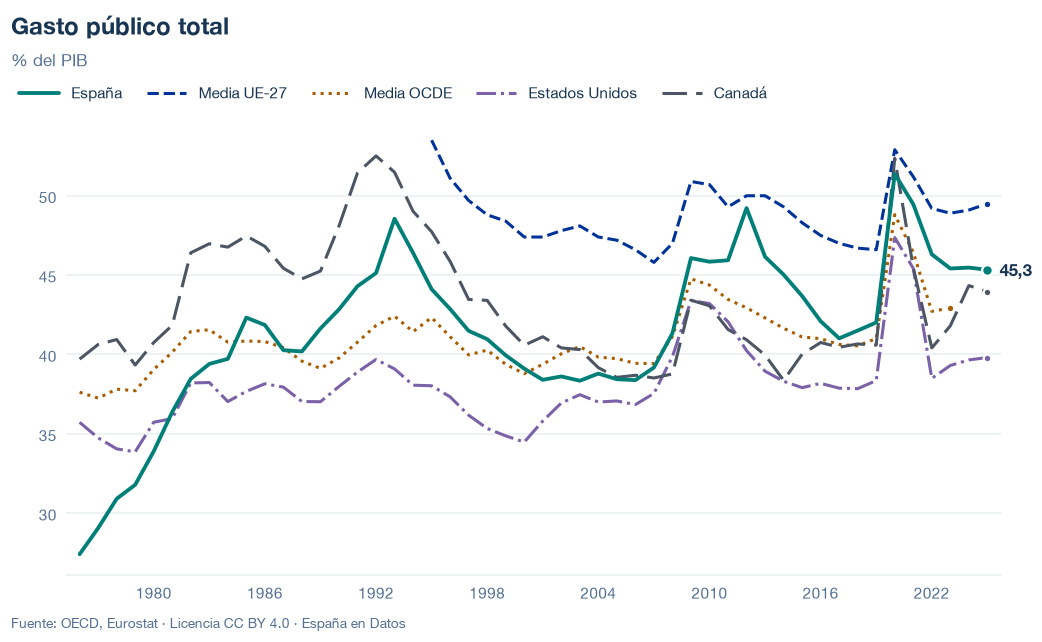

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/gasto-publico-total.json y data/gasto-publico-total.csv


## 6. Fuentes, notas y licencia

- OCDE, Economic Outlook (`OECD.ECO.MAD,DSD_EO@DF_EO`, medida `YPGTQ`): España, EE. UU., Canadá y OCDE; `GDP` y `PPP` de los países miembros, solo para contrastar la ponderación del agregado. El último año observado de cada serie sale del fichero «Last historical points» de la edición, enlazado desde la descripción del dataflow junto con la documentación de la base de datos (agregados en el anexo 6; cobertura de las cuentas públicas en el anexo A3).
- Eurostat, `gov_10a_main`: UE-27, y España para el contraste.

La fecha de consulta de cada serie está en `fuentes` del JSON; las notas, en `notas`, incluyen el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.